# Excercise - Decision Trees
---

In this exercise, we will create decision trees with post-pruning using a medical dataset. As a challenge, on this *application scenario*, we will deal with mixed data (numerical and categorical). Furthermore, we will compare decision trees with k-NN and again tune the hyperparameter k.

Imports:

In [184]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
from sklearn.preprocessing import OrdinalEncoder
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score, f1_score
from sklearn import tree
from sklearn.tree import export_text
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import MinMaxScaler
from sklearn.ensemble import RandomForestClassifier

## Heart Disease Data Set

We will use the [Heart Disease Data Set](https://archive.ics.uci.edu/ml/datasets/heart+disease) (available in the `data/`folder) for this exercise. It contains patient data from a hospital in Cleveland with the following attributes:

* **age**: age in years
* **sex**: sex
* **cp**: chest pain type
        -- Value 1: typical angina
        -- Value 2: atypical angina
        -- Value 3: non-anginal pain
        -- Value 4: asymptomatic
* **trestbps**: resting blood pressure (in mm Hg on admission to the hospital)
* **chol**: serum cholestoral in mg/dl
* **fbs**: (fasting blood sugar > 120 mg/dl)  (true; false)
* **restecg**: resting electrocardiographic results
        -- Value 0: normal
        -- Value 1: having ST-T wave abnormality (T wave inversions and/or ST 
                    elevation or depression of > 0.05 mV)
        -- Value 2: showing probable or definite left ventricular hypertrophy
                    by Estes' criteria
* **thalach**: maximum heart rate achieved
* **exang**: exercise induced angina (yes; no)
* **oldpeak:** ST depression induced by exercise relative to rest
* **slope:** the slope of the peak exercise ST segment
        -- Value 1: upsloping
        -- Value 2: flat
        -- Value 3: downsloping
* **ca:** number of major vessels (0-3) colored by flourosopy
* **thal:** normal; fixed defect; reversable defect
* **num:** 0 (no presence) to 4

For our classification model, a precise understanding of the individual attributes and their meaning is not important. However, as you know, in Data Science it would not harm to have a good undestanding of the applicaiton domain as well -- working  **interdisciplinary** helps us to understand the validity of the data as well as the resulting ML models.

For more information about the data, see `data/heart-disease.names`.


## Import the data

In [185]:
df = pd.read_csv('./data/heart_desease.csv')

In [186]:
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63.0,male,typical angina,145.0,233.0,True,ventricual hypertrophy,150.0,yes,2.3,downsloping,0,fixed defect,0
1,67.0,male,asymptomatic,160.0,286.0,False,ventricual hypertrophy,108.0,no,1.5,flat,3,normal,2
2,67.0,male,asymptomatic,120.0,229.0,False,ventricual hypertrophy,129.0,no,2.6,flat,2,reversable defect,1
3,37.0,male,non-anginal pain,130.0,250.0,False,normal,187.0,yes,3.5,downsloping,0,normal,0
4,41.0,female,atypical angina,130.0,204.0,False,ventricual hypertrophy,172.0,yes,1.4,upsloping,0,normal,0


In [187]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    float64
 1   sex       303 non-null    str    
 2   cp        303 non-null    str    
 3   trestbps  303 non-null    float64
 4   chol      303 non-null    float64
 5   fbs       303 non-null    bool   
 6   restecg   303 non-null    str    
 7   thalach   303 non-null    float64
 8   exang     303 non-null    str    
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    str    
 11  ca        303 non-null    str    
 12  thal      303 non-null    str    
 13  num       303 non-null    int64  
dtypes: bool(1), float64(5), int64(1), str(7)
memory usage: 31.2 KB


As you can see, the dataset has **numerical** and **categorical** features. The `num` feature is our target. 

Ideally, we would use a ID3 decision tree here, but since `scikit-learn` does not ship with this algorithm (and the `chefboost` package is maybe too different to use for now and not really trustworthy), we will use a **CART** with **numeric values** in the following.

## Preprocessing

The target variable (*label*) that we want to predict is stored in the variable `num`. This indicates 5 stages of narrowing the diameter of vessels, which determines the presence of heart disease. For the value $0$, the patient is healthy. According to the publication on this data set, we want to use this classification problem as a **binary classification  problem**. This means that we only distinguish between the normal healthy value ($\hat = 0$) and the presence of a disease ($1,2,3,4$).

Therefore, please first binarize ($0,1$) the target variable. Store the result in the dataframe and in the variable `y`.

<h4><span style="color:blue">1. Binarize the target variable to 0: healthy and 1: heart disease.</span></h4>

**Note**: Do not use the LabelEncoder for this task, since this would end up in 5 differnt classes and we only want two (0,1)!

In [188]:
# 0 = healthy and  1 = heart disease 
df['num'] = np.where(df['num'] > 0, 1, 0)
y = df['num']
print(df['num'].unique())   

[0 1]


In order to use the categorical variables as input for the CART decision tree model, they must be converted into numerical values. The easiest way to achieve this is with *Integer Encoding* (also *Ordinal Encoding*). Each value expression of a variable is simply assigned an integer value. This type of coding is actually only appropriate if the features are ordinally scaled, i.e. if there is a fixed relationship (order) between the categories.

**Note**: Actually this is not correct for some features in our case. For `sex` it would be correct, since there are only two genders present in the data set, for `restecg` there will be an (probably incorrect) ordering assumed!

<h4><span style="color:blue">2. Apply an integer encoding. Please store the resulting feature matrix (containing all encoded and (untouched) numeric variables) as `X_enc`.</span></h4>


**Hints**: 
- Copy the data first into a new dataframe, we need to use `df` later again
- You might use the [OrdinalEncoder](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.OrdinalEncoder.html) from `scikit-learn`
- Make sure the target variable(s) `num` and `y` are *not* part of X_enc
- Of course, every feature in question needs to be addressed/encoded separately; do **not** encode numerical features!
- Elegant solution: You can also loop over columns in question, maybe `df.select_dtypes(include=['strprint(df.dtypes)', 'bool']).columns` helps you to write less code...
- It is okay to encode the categorical vales here with an arbitrary number. In a better data preparation, you could think of taking the ordinal features and encode them properly (i.e. slope: 0-upsloping, 1-flat, 2-downsloping). However you need to be a medical expert for that, I guess!

In [189]:
# copy of dataset without class label num 
X_enc = df.drop(columns=['num']).copy()

# only encode categorical data not numerical
cat_cols = X_enc.select_dtypes(include=['str', 'bool']).columns
print("cat columns", cat_cols)

encoder = OrdinalEncoder()
X_enc[cat_cols] = encoder.fit_transform(X_enc[cat_cols]).astype(int)
print(X_enc.head())
print(X_enc.info())

cat columns Index(['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'ca', 'thal'], dtype='str')
    age  sex  cp  trestbps   chol  fbs  restecg  thalach  exang  oldpeak  \
0  63.0    1   3     145.0  233.0    1        2    150.0      1      2.3   
1  67.0    1   0     160.0  286.0    0        2    108.0      0      1.5   
2  67.0    1   0     120.0  229.0    0        2    129.0      0      2.6   
3  37.0    1   2     130.0  250.0    0        1    187.0      1      3.5   
4  41.0    0   1     130.0  204.0    0        2    172.0      1      1.4   

   slope  ca  thal  
0      0   0     0  
1      1   3     1  
2      1   2     2  
3      0   0     1  
4      2   0     1  
<class 'pandas.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 13 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    float64
 1   sex       303 non-null    int64  
 2   cp        303 non-null    int64  
 3   trestbps  303 non-null    f

## Decision Tree Classifier

<h4><span style="color:blue">3. Now, please split your training/test data with having 30% of records in the test set using <b>stratified sampling</b>. Also, please select <b>random_state=0</b> such that you can repeat the experiment later on with a different X (instead of X_enc) having the same instances in the same set.</span></h4>


In [190]:
# Split into train/test:
X_train, X_test, y_train, y_test = train_test_split(X_enc, y ,test_size=0.3,stratify=y,random_state=0)

Now it is time to train your Decision Tree Classifier using X_enc. Please use **gini** measure and perform a post-pruning to avoid overfitting. 

<h4><span style="color:blue">4. Train your decision tree and take the notes into account.</span></h4>

**Notes:**
* Use **gini** measure/criterion and set again **random_state=0**.
* perform a post-pruning of the tree
* Print the accuracy of the model on the test set after training
* Which features are most important to build the tree? (c.f. parameter `feature_importances_` of your pruned tree [here](https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeClassifier.html#sklearn.tree.DecisionTreeClassifier.feature_importances_)). Print these features ordered by importance.
* Visualize your tree 

Training with post-pruning:

In [191]:
clf = DecisionTreeClassifier(criterion='gini', random_state=0)
path = clf.cost_complexity_pruning_path(X_train, y_train)
ccp_alphas, impurities = path.ccp_alphas, path.impurities

parameters = {'ccp_alpha': ccp_alphas[:-1].tolist()}
gs = GridSearchCV(DecisionTreeClassifier(criterion='gini', random_state=0),
                  parameters, cv=10, refit=True)
gs.fit(X_train, y_train)
print(gs.best_params_)

tree_best = gs.best_estimator_


{'ccp_alpha': 0.011230907457322553}


Accuracy:

In [192]:
pred = tree_best.predict(X_test)

print('Test accuracy', accuracy_score(y_test, pred))
print('f1:', f1_score(y_test, pred))

Test accuracy 0.8241758241758241
f1: 0.7837837837837838


Feature Importance:

In [193]:
importances = pd.Series(tree_best.feature_importances_, index=X_enc.columns)
print(importances.sort_values(ascending=False))

cp          0.347980
oldpeak     0.188277
ca          0.150628
age         0.112995
trestbps    0.083439
exang       0.066352
thal        0.050327
chol        0.000000
sex         0.000000
thalach     0.000000
restecg     0.000000
fbs         0.000000
slope       0.000000
dtype: float64


Visualization (make sure resolution is large enough to read text):

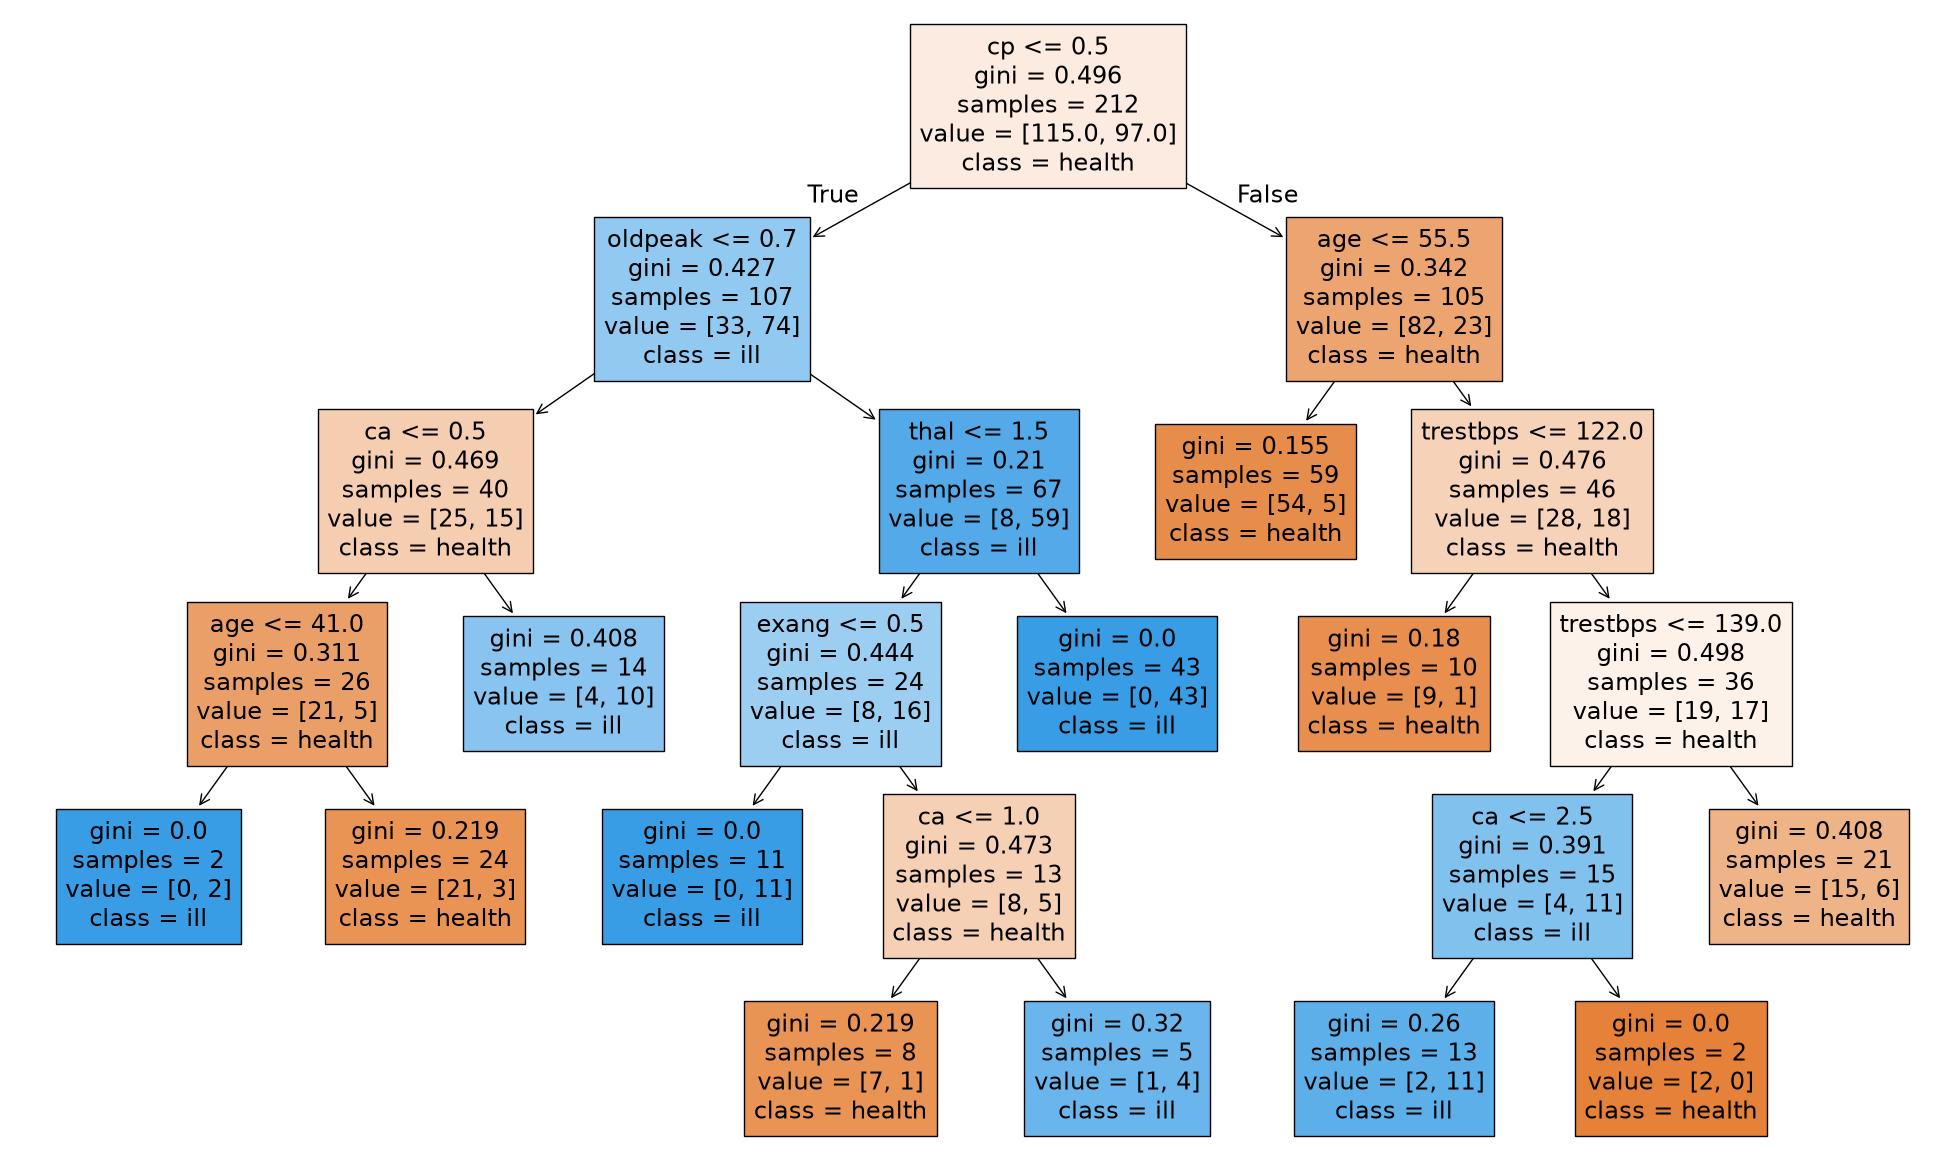

In [194]:
fig = plt.figure(figsize=(25, 15))
text = tree.plot_tree(tree_best,
                      feature_names=X_enc.columns.to_list(),
                      class_names=['health', 'ill'],
                      filled=True)
plt.show()

<h4><span style="color:blue">5. Print the rules of the tree as text:</span></h4>

In [195]:
r = export_text(tree_best, feature_names=X_enc.columns.to_list())
print(r)

|--- cp <= 0.50
|   |--- oldpeak <= 0.70
|   |   |--- ca <= 0.50
|   |   |   |--- age <= 41.00
|   |   |   |   |--- class: 1
|   |   |   |--- age >  41.00
|   |   |   |   |--- class: 0
|   |   |--- ca >  0.50
|   |   |   |--- class: 1
|   |--- oldpeak >  0.70
|   |   |--- thal <= 1.50
|   |   |   |--- exang <= 0.50
|   |   |   |   |--- class: 1
|   |   |   |--- exang >  0.50
|   |   |   |   |--- ca <= 1.00
|   |   |   |   |   |--- class: 0
|   |   |   |   |--- ca >  1.00
|   |   |   |   |   |--- class: 1
|   |   |--- thal >  1.50
|   |   |   |--- class: 1
|--- cp >  0.50
|   |--- age <= 55.50
|   |   |--- class: 0
|   |--- age >  55.50
|   |   |--- trestbps <= 122.00
|   |   |   |--- class: 0
|   |   |--- trestbps >  122.00
|   |   |   |--- trestbps <= 139.00
|   |   |   |   |--- ca <= 2.50
|   |   |   |   |   |--- class: 1
|   |   |   |   |--- ca >  2.50
|   |   |   |   |   |--- class: 0
|   |   |   |--- trestbps >  139.00
|   |   |   |   |--- class: 0



## One-hot Encoding

As already mentioned, the ordinal encoding is not very helpful, if we really have categorical instead of ordinal data. To this end, we will now apply a one-hot-encoding (OHE) and check, if we can get a better accuracy. 

<h4><span style="color:blue">6. Apply OHE and store the results in X_ohe.</span></h4>

**Hints:**
* As in previous exercise, make sure to create a copy of the original df first.
* Make sure to only use **one-hot encoding for columns having more than two categories**!
* For features having two categories only, use OrdinalEncoder.
* You could use the OneHotEncoder from `scikit-learn`, but there is a more convinient way, have a look at the [get_dummies](https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.get_dummies.html) method from pandas!
* As a first step, find the number of (different) categories for each of the features in question, features in question are:

In [196]:
# copy of dataset without class label num 
X_ohe = df.drop(columns=['num']).copy()
cat_cols = X_ohe.select_dtypes(include=['str', 'bool']).columns

n_cat = X_ohe[cat_cols].nunique()
print(n_cat)


sex        2
cp         4
fbs        2
restecg    3
exang      2
slope      3
ca         5
thal       4
dtype: int64


In [197]:
bin_cols   = n_cat[n_cat == 2].index   # 2 categories -> OrdinalEncoder
multi_cols = n_cat[n_cat > 2].index    # more than 2 -> One-Hot Encoder

print(list(bin_cols))
print(list(multi_cols))

['sex', 'fbs', 'exang']
['cp', 'restecg', 'slope', 'ca', 'thal']


In [198]:
# encode ordinal and one-hot
X_ohe[bin_cols] = OrdinalEncoder().fit_transform(X_ohe[bin_cols]).astype(int)
X_ohe = pd.get_dummies(X_ohe, columns=multi_cols, dtype=int)

print(X_ohe.shape)
print(X_ohe.dtypes)


(303, 27)
age                               float64
sex                                 int64
trestbps                          float64
chol                              float64
fbs                                 int64
thalach                           float64
exang                               int64
oldpeak                           float64
cp_asymptomatic                     int64
cp_atypical angina                  int64
cp_non-anginal pain                 int64
cp_typical angina                   int64
restecg_ST-T wave abnormality       int64
restecg_normal                      int64
restecg_ventricual hypertrophy      int64
slope_downsloping                   int64
slope_flat                          int64
slope_upsloping                     int64
ca_0                                int64
ca_1                                int64
ca_2                                int64
ca_3                                int64
ca_unknown                          int64
thal_fixed defect       

If your X_enc has now 27 dimensions, you did everything correctly!

<h4><span style="color:blue">7. Split the data again (same way as earlier with same random state) and repeat the experiments from exercise (4), including plotting the tree. Did the accuracy get better?</span></h4>

In [199]:
acc_enc = accuracy_score(y_test, tree_best.predict(X_test))

In [200]:
X_train, X_test, y_train, y_test = train_test_split(X_ohe, y,test_size=0.3,stratify=y,random_state=0)

In [201]:
clf = DecisionTreeClassifier(criterion='gini', random_state=0)
path = clf.cost_complexity_pruning_path(X_train, y_train)
ccp_alphas, impurities = path.ccp_alphas, path.impurities

parameters = {'ccp_alpha': ccp_alphas[:-1].tolist()}
gs = GridSearchCV(DecisionTreeClassifier(criterion='gini', random_state=0),
                  parameters, cv=10, refit=True)
gs.fit(X_train, y_train)
print(gs.best_params_)

tree_ohe = gs.best_estimator_

{'ccp_alpha': 0.007861635220125786}


In [202]:
# accuracy
acc_ohe = accuracy_score(y_test, tree_ohe.predict(X_test))
print("Accuracy with X_enc:", acc_enc)
print("Accuracy with X_ohe:", acc_ohe)

importances = pd.Series(tree_ohe.feature_importances_, index=X_ohe.columns)
print(importances.sort_values(ascending=False))


Accuracy with X_enc: 0.8241758241758241
Accuracy with X_ohe: 0.7472527472527473
thal_normal                       0.324605
cp_asymptomatic                   0.195805
age                               0.102120
ca_0                              0.091458
chol                              0.061871
oldpeak                           0.056660
thalach                           0.053217
trestbps                          0.050284
slope_flat                        0.032868
sex                               0.031113
exang                             0.000000
cp_non-anginal pain               0.000000
cp_atypical angina                0.000000
fbs                               0.000000
cp_typical angina                 0.000000
restecg_ventricual hypertrophy    0.000000
restecg_normal                    0.000000
slope_downsloping                 0.000000
restecg_ST-T wave abnormality     0.000000
slope_upsloping                   0.000000
ca_1                              0.000000
ca_3             

In my case the accuracy got worse, but it depends on the random_state choosen -- maybe a nested CV would be better in this case!

Visualizing the tree:

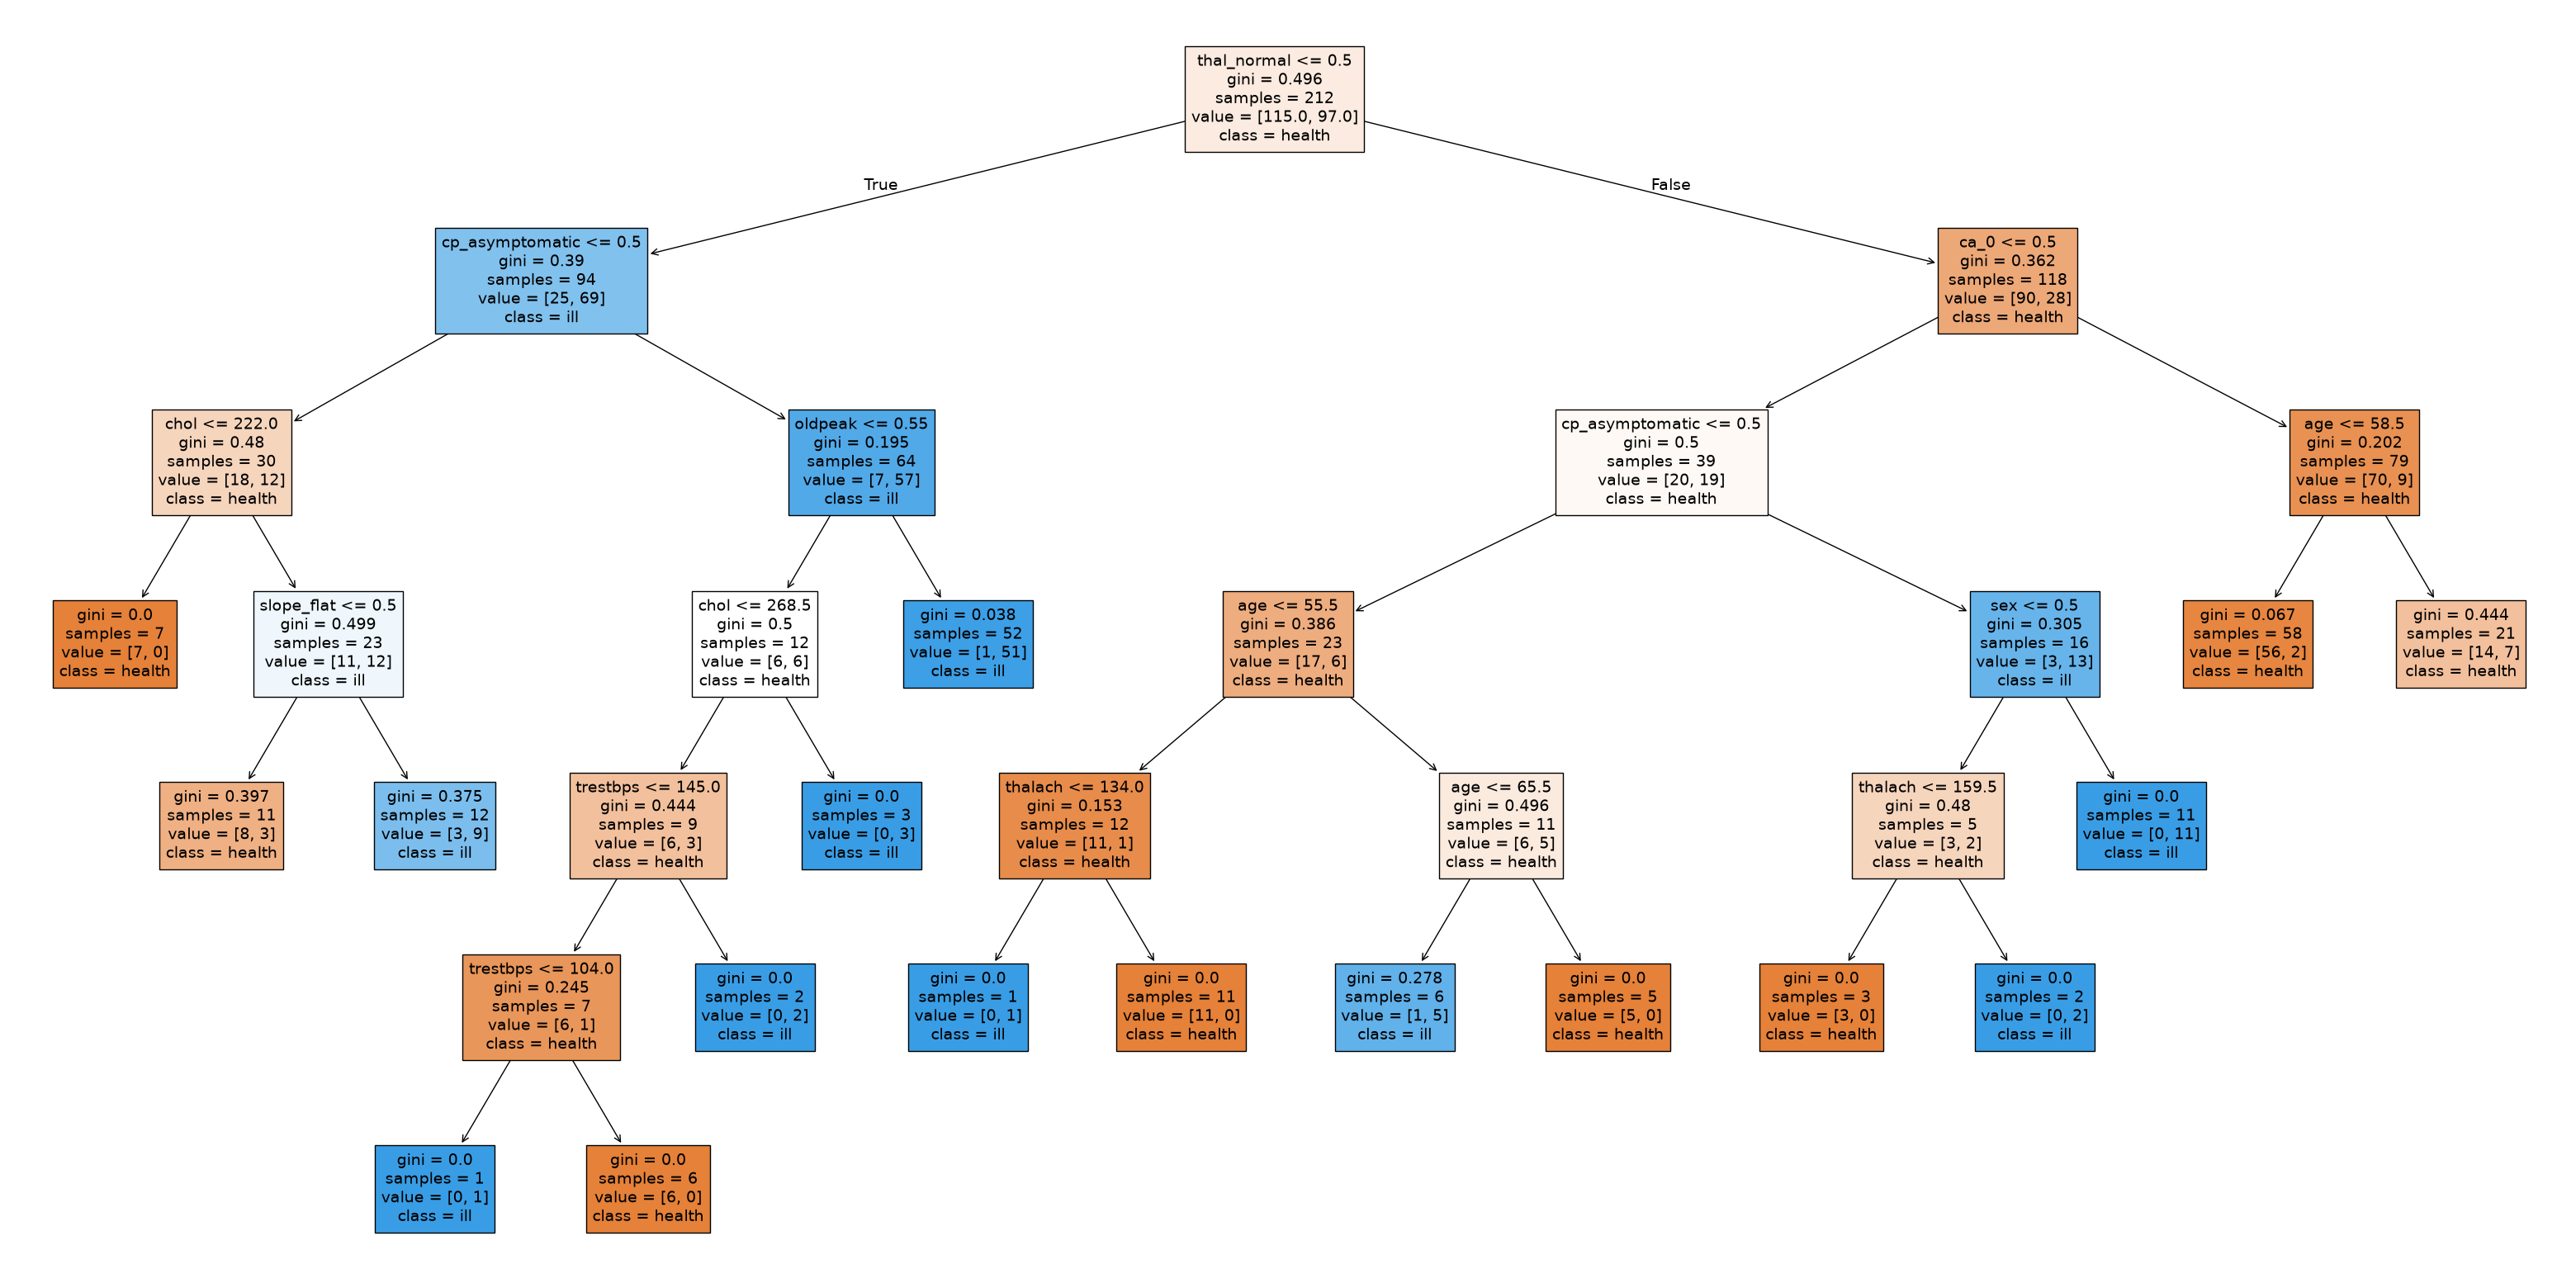

In [203]:
fig = plt.figure(figsize=(40, 20))
text = tree.plot_tree(tree_ohe,
                      feature_names=X_ohe.columns.to_list(),
                      class_names=['health', 'ill'],
                      filled=True)
plt.show()

Have a look at the feature "cp", which was the most discriminate feature for our first tree. After the one-hot-encoding, we could spot that only the category "asymtomatic" was important -- the other features (and thus categories) seem to be irrelevant.

**Note**: This finding could be different if you did not use random_state=0 in the train_test_split method in some (unlucky) cases...

## K-Nearest Neighbors

As a comparison, let's check how well K-NN is performing on the data. To get a good comparison, we want to use the OrdinalEncoding and the One-hot-encoding. In every case, we want to determine a good $k$ using hyperparameter tuning with CV.

<h4><span style="color:blue">8. Apply k-NN on the ordinal and the one-hot-encoded data. Tune $k$ in both experiments.</span></h4>

**Hints**
- Don't forget to **normalize** your data (use MinMaxScaler)!
- Make sure again that you use the same train-/test split as above

In [204]:
# accuracy for tuned K-NN on X_ohe.
Xo_train, Xo_test, yo_train, yo_test = train_test_split(X_ohe, y, test_size=0.3, stratify=y, random_state=0)

pipe = Pipeline([
    ('scaler', MinMaxScaler()),
    ('knn', KNeighborsClassifier())
])

param_grid = {
    'knn__n_neighbors': range(1, 40, 2),
    'knn__weights': ['uniform', 'distance'],
    'knn__metric': ['euclidean', 'manhattan']
}

grid_ohe = GridSearchCV(
    pipe, 
    param_grid, 
    cv=10, 
    scoring='accuracy', 
    n_jobs=-1,
    refit=True
)

grid_ohe.fit(Xo_train, yo_train)

best_model_ohe = grid_ohe.best_estimator_
y_pred_ohe = best_model_ohe.predict(Xo_test)

print("Best Parameter:", grid_ohe.best_params_)
print("CV-Score:", grid_ohe.best_score_)
print("Accuracy (X_ohe):", accuracy_score(yo_test, y_pred_ohe))

Best Parameter: {'knn__metric': 'manhattan', 'knn__n_neighbors': 29, 'knn__weights': 'distance'}
CV-Score: 0.8536796536796537
Accuracy (X_ohe): 0.8131868131868132


In [205]:
# accuracy for tuned K-NN on X_enc
Xe_train, Xe_test, ye_train, ye_test = train_test_split(X_enc, y, test_size=0.3, stratify=y, random_state=0)

grid_enc = GridSearchCV(
    pipe, 
    param_grid, 
    cv=10, 
    scoring='accuracy', 
    n_jobs=-1,
    refit=True
)

grid_enc.fit(Xe_train, ye_train)

best_model_enc = grid_enc.best_estimator_
y_pred_enc = best_model_enc.predict(Xe_test)

print("Best Parameter:", grid_enc.best_params_)
print("CV-Score:", grid_enc.best_score_)
print("Accuracy (X_enc):", accuracy_score(ye_test, y_pred_enc))

Best Parameter: {'knn__metric': 'manhattan', 'knn__n_neighbors': 23, 'knn__weights': 'uniform'}
CV-Score: 0.8303030303030303
Accuracy (X_enc): 0.8131868131868132


Looks like K-NN is having a similar performance than the tree.. 
(In my case the post-pruned tree was a bit better than k-NN, but depends on your split..)


To give the Trees a last chance on this dataset, let's try a **Random Forrest** on the data.

## Random Forest

<h4><span style="color:blue">9. As a last experiment, create a Random Forest with small trees and get the accuracy on the test set.</span></h4>

**Hints**:
- You can do this exercise only after **next weeks lecture**, please be patient for another 7 days..
- No need to tune hyperparameters, try to "guess" good values
- Find out by yourself, if X_enc or X_ohe should be used...
- Again, no normalization required for RF

In [206]:
rf_ohe = RandomForestClassifier(n_estimators=100, max_depth=5, random_state=0)
rf_ohe.fit(Xo_train, yo_train)
print("Accuracy (X_ohe):", accuracy_score(yo_test, rf_ohe.predict(Xo_test)))

rf_enc = RandomForestClassifier(n_estimators=100, max_depth=5, random_state=0)
rf_enc.fit(Xe_train, ye_train)
print("Accuracy (X_enc):", accuracy_score(ye_test, rf_enc.predict(Xe_test)))

Accuracy (X_ohe): 0.8571428571428571
Accuracy (X_enc): 0.8571428571428571


It seems like the RF performs better than the single tree(s) as well as the K-NN!